<a href="https://colab.research.google.com/github/adhithya032006/DAV-LAB-/blob/main/Employee_outlier_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from google.colab import files


In [ ]:

uploaded = files.upload()

df = pd.read_csv("employee_salary_dataset.csv")

print("Employee Salary Dataset:")
print(df)


Saving employee_salary_dataset.csv to employee_salary_dataset.csv
Employee Salary Dataset:
    EmployeeID         Name  Department  Experience_Years Education_Level  \
0            1   Employee_1   Marketing                15          Master   
1            2   Employee_2  Operations                 7        Bachelor   
2            3   Employee_3          IT                12     High School   
3            4   Employee_4  Operations                 8             PhD   
4            5   Employee_5  Operations                15          Master   
5            6   Employee_6     Finance                 3     High School   
6            7   Employee_7          IT                14             PhD   
7            8   Employee_8          IT                17             PhD   
8            9   Employee_9          IT                 4        Bachelor   
9           10  Employee_10  Operations                18     High School   
10          11  Employee_11   Marketing                 8     

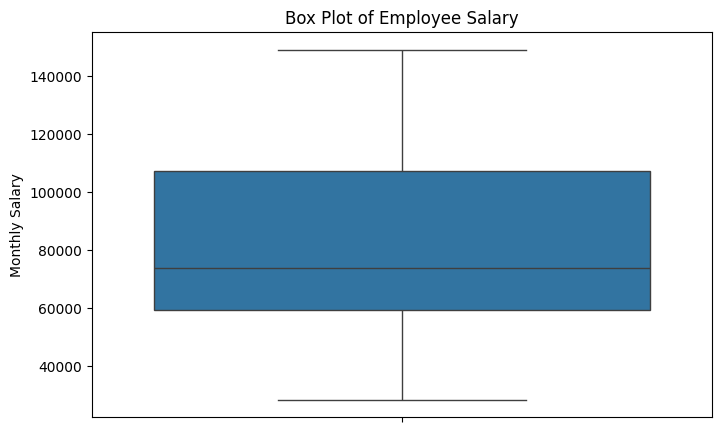

In [ ]:

plt.figure(figsize=(8, 5))

sns.boxplot(y=df['Monthly_Salary'])

plt.title("Box Plot of Employee Salary")
plt.ylabel("Monthly Salary")
plt.show()


In [ ]:

Q1 = df['Monthly_Salary'].quantile(0.25)
Q3 = df['Monthly_Salary'].quantile(0.75)

print("Q1 =", Q1)
print("Q3 =", Q3)

IQR = Q3 - Q1

print("IQR =", IQR)

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limit =", lower_limit)
print("Upper Limit =", upper_limit)

outliers_iqr = df[
    (df['Monthly_Salary'] < lower_limit) |
    (df['Monthly_Salary'] > upper_limit)
]

print("\nOutliers detected using IQR:")
print(outliers_iqr)


Q1 = 59424.0
Q3 = 107219.0
IQR = 47795.0
Lower Limit = -12268.5
Upper Limit = 178911.5

Outliers detected using IQR:
Empty DataFrame
Columns: [EmployeeID, Name, Department, Experience_Years, Education_Level, Age, Gender, City, Monthly_Salary]
Index: []


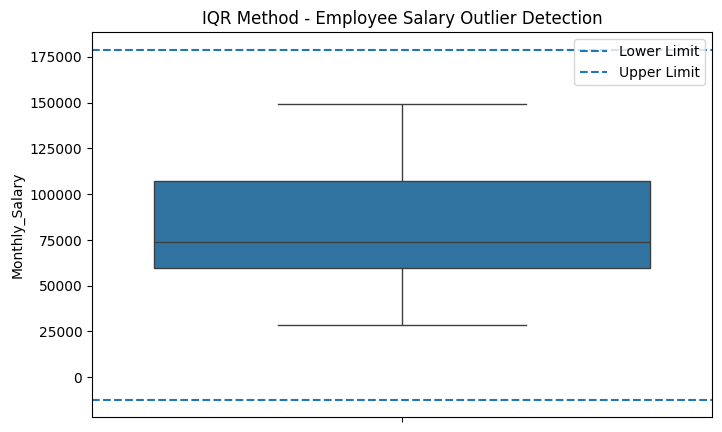

In [ ]:

plt.figure(figsize=(8, 5))

sns.boxplot(y=df['Monthly_Salary'])

plt.axhline(lower_limit, linestyle='--', label='Lower Limit')
plt.axhline(upper_limit, linestyle='--', label='Upper Limit')

plt.title("IQR Method - Employee Salary Outlier Detection")
plt.legend()
plt.show()


In [ ]:

df['Salary_IQR_Capped'] = df['Monthly_Salary'].clip(
    lower=lower_limit,
    upper=upper_limit
)

print(df[['Monthly_Salary', 'Salary_IQR_Capped']])


    Monthly_Salary  Salary_IQR_Capped
0           111416             111416
1            95271              95271
2            69064              69064
3            95091              95091
4           132450             132450
5            65818              65818
6            70525              70525
7            44830              44830
8            42429              42429
9            31893              31893
10          141381             141381
11          104909             104909
12           72333              72333
13           28436              28436
14           99290              99290
15          101213             101213
16           30895              30895
17           44738              44738
18           55746              55746
19           74377              74377
20           73404              73404
21           79045              79045
22          122888             122888
23           64790              64790
24          132455             132455
25          

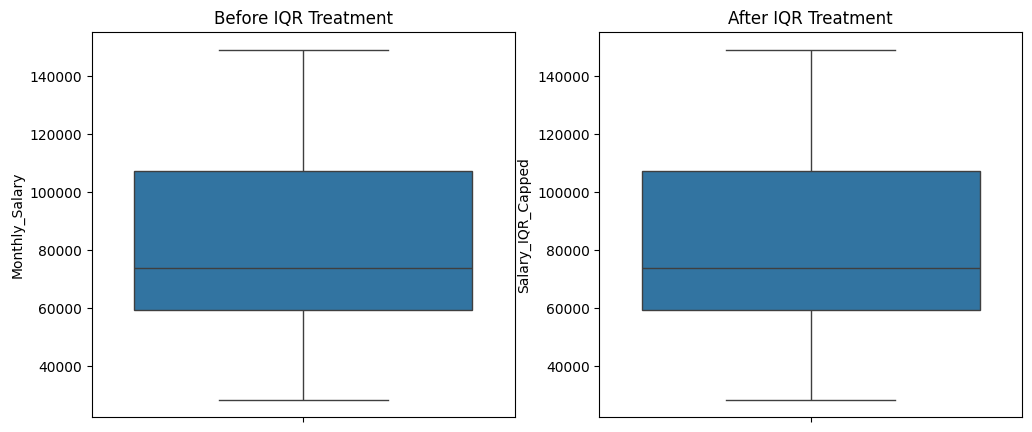

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df['Monthly_Salary'], ax=axes[0])
axes[0].set_title("Before IQR Treatment")

sns.boxplot(y=df['Salary_IQR_Capped'], ax=axes[1])
axes[1].set_title("After IQR Treatment")

plt.show()


In [ ]:

df['Z_score'] = stats.zscore(df['Monthly_Salary'])

print(df[['Monthly_Salary', 'Z_score']])


    Monthly_Salary   Z_score
0           111416  0.877734
1            95271  0.391212
2            69064 -0.398523
3            95091  0.385788
4           132450  1.511584
5            65818 -0.496340
6            70525 -0.354497
7            44830 -1.128803
8            42429 -1.201156
9            31893 -1.518653
10          141381  1.780715
11          104909  0.681649
12           72333 -0.300013
13           28436 -1.622828
14           99290  0.512323
15          101213  0.570272
16           30895 -1.548728
17           44738 -1.131575
18           55746 -0.799855
19           74377 -0.238418
20           73404 -0.267739
21           79045 -0.097750
22          122888  1.223438
23           64790 -0.527318
24          132455  1.511735
25           30600 -1.557617
26          119660  1.126163
27          118179  1.081534
28           65764 -0.497967
29           99543  0.519947
30           70714 -0.348801
31           81835 -0.013675
32          127946  1.375858
33          13

In [ ]:

z_outliers = df[abs(df['Z_score']) > 3]

print("Outliers detected using Z-score:")
print(z_outliers)

df['Z_Outlier'] = abs(df['Z_score']) > 3

print(df[['Monthly_Salary', 'Z_score', 'Z_Outlier']])


Outliers detected using Z-score:
Empty DataFrame
Columns: [EmployeeID, Name, Department, Experience_Years, Education_Level, Age, Gender, City, Monthly_Salary, Salary_IQR_Capped, Z_score]
Index: []
    Monthly_Salary   Z_score  Z_Outlier
0           111416  0.877734      False
1            95271  0.391212      False
2            69064 -0.398523      False
3            95091  0.385788      False
4           132450  1.511584      False
5            65818 -0.496340      False
6            70525 -0.354497      False
7            44830 -1.128803      False
8            42429 -1.201156      False
9            31893 -1.518653      False
10          141381  1.780715      False
11          104909  0.681649      False
12           72333 -0.300013      False
13           28436 -1.622828      False
14           99290  0.512323      False
15          101213  0.570272      False
16           30895 -1.548728      False
17           44738 -1.131575      False
18           55746 -0.799855      False
19 

In [ ]:

mean = df['Monthly_Salary'].mean()
std = df['Monthly_Salary'].std()

lower_z_limit = mean - 3 * std
upper_z_limit = mean + 3 * std

print("Lower Z-score limit =", lower_z_limit)
print("Upper Z-score limit =", upper_z_limit)

df['Salary_Z_Capped'] = df['Monthly_Salary'].clip(
    lower=lower_z_limit,
    upper=upper_z_limit
)

print(df[['Monthly_Salary', 'Salary_Z_Capped']])


Lower Z-score limit = -18275.51369881806
Upper Z-score limit = 182853.11369881808
    Monthly_Salary  Salary_Z_Capped
0           111416           111416
1            95271            95271
2            69064            69064
3            95091            95091
4           132450           132450
5            65818            65818
6            70525            70525
7            44830            44830
8            42429            42429
9            31893            31893
10          141381           141381
11          104909           104909
12           72333            72333
13           28436            28436
14           99290            99290
15          101213           101213
16           30895            30895
17           44738            44738
18           55746            55746
19           74377            74377
20           73404            73404
21           79045            79045
22          122888           122888
23           64790            64790
24          132455

    Monthly_Salary  Salary_IQR_Capped  Salary_Z_Capped
0           111416             111416           111416
1            95271              95271            95271
2            69064              69064            69064
3            95091              95091            95091
4           132450             132450           132450
5            65818              65818            65818
6            70525              70525            70525
7            44830              44830            44830
8            42429              42429            42429
9            31893              31893            31893
10          141381             141381           141381
11          104909             104909           104909
12           72333              72333            72333
13           28436              28436            28436
14           99290              99290            99290
15          101213             101213           101213
16           30895              30895            30895
17        

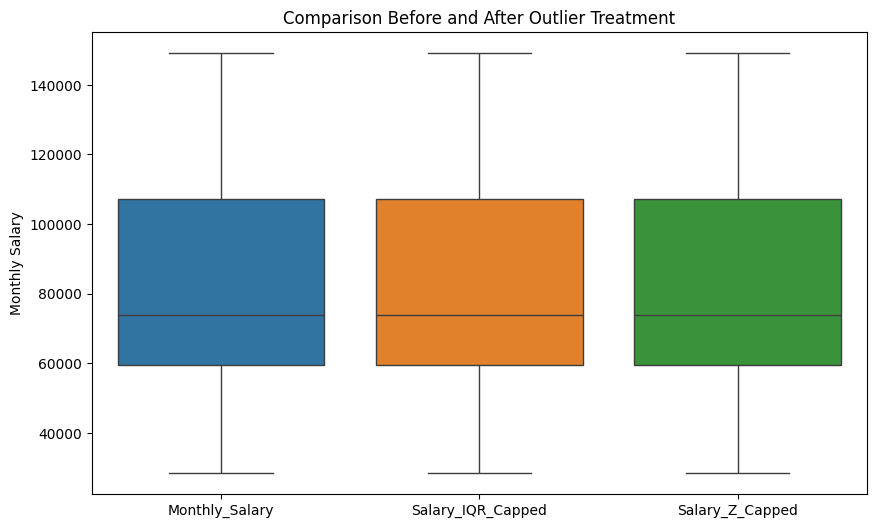

In [ ]:

print(df[[
    'Monthly_Salary',
    'Salary_IQR_Capped',
    'Salary_Z_Capped'
]])

plt.figure(figsize=(10, 6))

sns.boxplot(data=df[[
    'Monthly_Salary',
    'Salary_IQR_Capped',
    'Salary_Z_Capped'
]])

plt.title("Comparison Before and After Outlier Treatment")
plt.ylabel("Monthly Salary")
plt.show()
